# Chapter 7: Unsupervised Learning
**Buku:** *Practical Statistics for Data Scientists (2nd Edition)* — Peter Bruce, Andrew Bruce, & Peter Gedeck

---

## 1. Chapter Summary
Di bab-bab sebelumnya, kita telah membahas pemodelan *supervised learning* di mana kita memiliki variabel target ($Y$) yang ingin diprediksi. Bab ini berfokus pada **Unsupervised Learning**, yaitu teknik analisis di mana tidak ada label target, dan tujuan utamanya adalah untuk menemukan pola, struktur, atau kelompok tersembunyi di dalam data.

Bab ini mencakup:
1. **Principal Component Analysis (PCA):** Teknik reduksi dimensi untuk menyederhanakan data yang kompleks dengan mencari kombinasi linier dari variabel-variabel asli.
2. **K-Means Clustering:** Algoritma pemisahan data ke dalam $K$ kelompok (klaster) berdasarkan jarak ke titik pusat (*centroid*).
3. **Hierarchical Clustering:** Teknik pengelompokan aglomeratif (dari bawah ke atas) yang hasil akhirnya dapat divisualisasikan menggunakan diagram pohon (*dendrogram*).
4. **Model-Based Clustering:** Menggunakan pendekatan statistik probabilitas, seperti *Gaussian Mixture Models* (GMM), untuk mendeteksi klaster.
5. **Scaling & Categorical Variables:** Standarisasi skala variabel numerik (z-scores) dan metode pengukuran jarak untuk data campuran (misal: Jarak Gower) sebelum melakukan *clustering*.

In [1]:
# Import library pendukung
%matplotlib inline
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn dan SciPy untuk Unsupervised Learning
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs
from scipy.cluster.hierarchy import linkage, dendrogram

# Definisi jalur folder data (sesuaikan dengan direktori Anda)
DATA = Path('../data')
SP500_DATA_CSV = DATA / 'sp500_data.csv.gz'

---
## 2. Principal Component Analysis (PCA)

### Theoretical Explanation
* **PCA:** Menemukan serangkaian sumbu linier baru (komponen utama) di mana data memiliki varians maksimum. Tujuannya adalah mereduksi jumlah dimensi data sambil mempertahankan sebanyak mungkin informasi (variasi) dari data aslinya.
* **Kombinasi Linier:** Komponen utama pertama ($Z_1$) adalah kombinasi linier dari variabel prediktor asli ($X_1, X_2, \dots, X_p$) yang memiliki varians terbesar:
  $$Z_1 = w_{1,1}X_1 + w_{1,2}X_2 + \dots + w_{1,p}X_p$$
* **Loadings (Bobot):** Nilai $w$ dalam persamaan di atas disebut *loadings*, yang menunjukkan seberapa besar kontribusi masing-masing variabel asli terhadap komponen utama tersebut.
* **Scree Plot:** Digunakan untuk melihat proporsi varians yang dijelaskan (*variance explained*) oleh masing-masing komponen utama, guna memutuskan berapa banyak komponen yang harus dipertahankan.

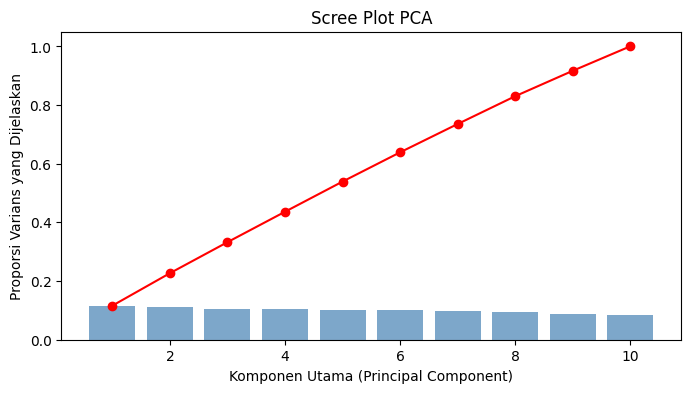

Loadings untuk Komponen Utama 1 (PC1):


,Loadings PC1
SLB,0.641235
AAPL,0.163030
CSCO,0.091708
MSFT,-0.019059
WFC,-0.109374
CVX,-0.113470
INTC,-0.182130
JPM,-0.218566
COP,-0.444512
XOM,-0.500094


In [2]:
# Memuat data harga saham S&P 500
try:
    sp500_px = pd.read_csv(SP500_DATA_CSV, index_col=0)
    # Memilih beberapa saham teknologi sebagai contoh
    oil_px = sp500_px[['CVX', 'XOM']]
    syms = ['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP', 'JPM', 'WFC', 'USB']
    top_sp = sp500_px[syms]
except FileNotFoundError:
    # Dummy data saham jika file tidak ditemukan
    np.random.seed(42)
    top_sp = pd.DataFrame(np.random.normal(0, 1, size=(1000, 10)),
                          columns=['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP', 'JPM', 'WFC'])

# Melatih model PCA
pca = PCA(n_components=len(top_sp.columns))
pca.fit(top_sp)

# Menampilkan persentase varians yang dijelaskan (Variance Explained)
explained_variance = pca.explained_variance_ratio_

plt.figure(figsize=(8, 4))
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.7, color='steelblue')
plt.plot(range(1, len(explained_variance) + 1), np.cumsum(explained_variance), marker='o', color='red')
plt.xlabel('Komponen Utama (Principal Component)')
plt.ylabel('Proporsi Varians yang Dijelaskan')
plt.title('Scree Plot PCA')
plt.show()

# Menampilkan Loadings untuk Komponen Utama Pertama (PC1)
loadings = pd.DataFrame(pca.components_[0], index=top_sp.columns, columns=['Loadings PC1'])
loadings = loadings.sort_values(by='Loadings PC1', ascending=False)
print("Loadings untuk Komponen Utama 1 (PC1):")
display(loadings)

---
## 3. K-Means Clustering

### Theoretical Explanation
* **K-Means Algorithm:** Memisahkan data ke dalam $K$ kelompok sedemikian rupa sehingga jumlah kuadrat jarak antara setiap titik data dengan pusat klasternya (*centroid*) menjadi sekecil mungkin.
* **Langkah-langkah K-Means**:
  1. Pilih jumlah klaster $K$ dan inisialisasi $K$ *centroid* secara acak.
  2. Hitung jarak dari setiap titik data ke seluruh *centroid*, dan masukkan titik tersebut ke klaster dengan *centroid* terdekat.
  3. Perbarui posisi *centroid* dengan menghitung nilai rata-rata dari semua titik yang ada di klaster tersebut.
  4. Ulangi langkah 2 dan 3 sampai posisi *centroid* tidak lagi berubah (konvergen).
* **Elbow Method:** Karena $K$ harus ditentukan oleh pengguna, kita bisa mencoba beberapa nilai $K$ dan memplot *Within-Cluster Sum of Squares* (WSS). Titik di mana kurva mulai melandai secara tajam (membentuk 'siku') adalah jumlah $K$ yang optimal.

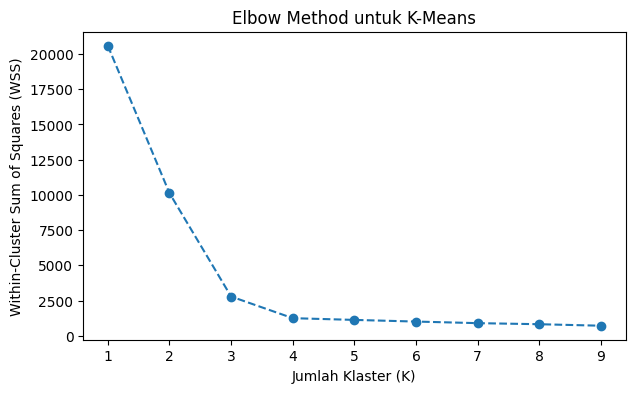

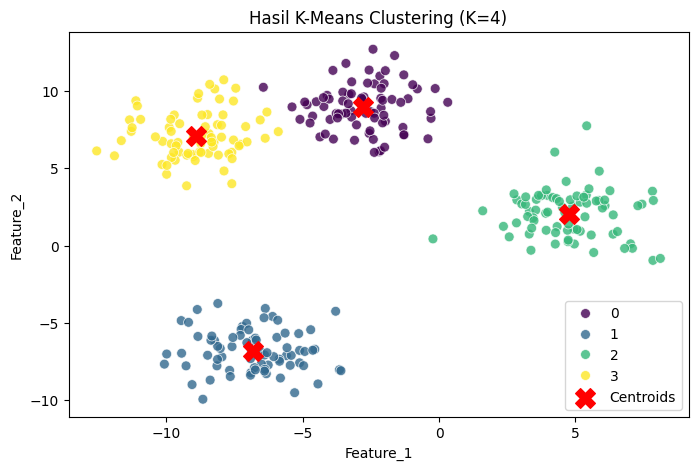

In [3]:
# Membuat dummy data 2D untuk clustering agar mudah divisualisasikan
X_blobs, y_blobs = make_blobs(n_samples=300, centers=4, cluster_std=1.5, random_state=42)
df_blobs = pd.DataFrame(X_blobs, columns=['Feature_1', 'Feature_2'])

# 1. Elbow Method untuk menentukan K optimal
wss = []
K_range = range(1, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_blobs)
    wss.append(kmeans.inertia_) # inertia_ adalah metrik WSS di scikit-learn

plt.figure(figsize=(7, 4))
plt.plot(K_range, wss, marker='o', linestyle='--')
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('Within-Cluster Sum of Squares (WSS)')
plt.title('Elbow Method untuk K-Means')
plt.show()

# 2. Menerapkan K-Means dengan K=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_blobs['Cluster'] = kmeans.fit_predict(df_blobs)
centroids = kmeans.cluster_centers_

# Visualisasi Hasil K-Means
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Feature_1', y='Feature_2', hue='Cluster', palette='viridis', data=df_blobs, s=50, alpha=0.8)
# Plot Centroids
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.title('Hasil K-Means Clustering (K=4)')
plt.legend()
plt.show()

---
## 4. Hierarchical Clustering

### Theoretical Explanation
* **Hierarchical Clustering (Agglomerative):** Berbeda dengan K-Means yang mulai dengan menentukan $K$, *hierarchical clustering* mulai dengan asumsi bahwa setiap titik data adalah satu klaster independen.
* Pada setiap iterasinya, algoritma ini mencari dua klaster yang jaraknya paling dekat (berdasarkan metrik disimilaritas) dan menggabungkannya menjadi satu klaster baru, terus-menerus hingga hanya tersisa satu klaster besar yang berisi seluruh data.
* **Dendrogram:** Visualisasi berbentuk pohon yang menunjukkan hierarki penggabungan kelompok. Sumbu vertikal menunjukkan "jarak" pada saat dua klaster digabungkan. Kita bisa memotong dendrogram pada ketinggian tertentu untuk mendapatkan jumlah klaster $K$ yang diinginkan.

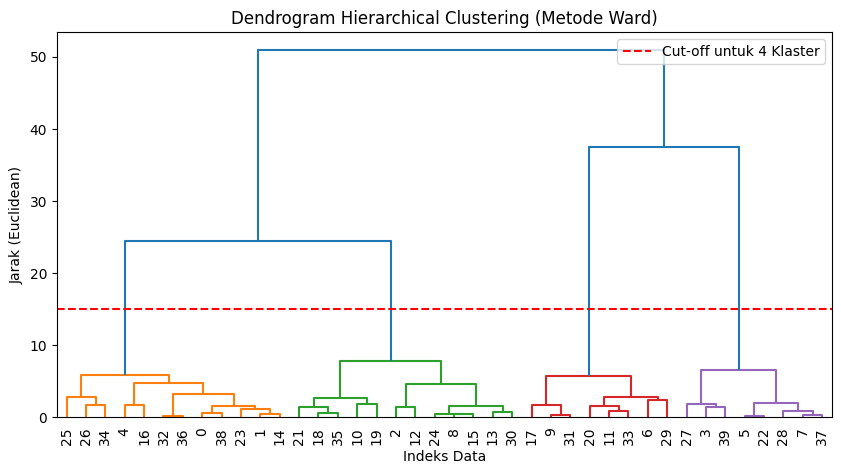

In [4]:
# Kita gunakan subset kecil dari data agar dendrogram mudah dibaca
X_subset = X_blobs[:40]

# Menghitung linkage matrix menggunakan metode penggabungan (misal 'ward')
Z = linkage(X_subset, method='ward', metric='euclidean')

# Visualisasi Dendrogram
plt.figure(figsize=(10, 5))
dendrogram(Z, leaf_rotation=90, leaf_font_size=10, color_threshold=15)
plt.axhline(y=15, color='r', linestyle='--', label='Cut-off untuk 4 Klaster')
plt.title('Dendrogram Hierarchical Clustering (Metode Ward)')
plt.xlabel('Indeks Data')
plt.ylabel('Jarak (Euclidean)')
plt.legend()
plt.show()

---
## 5. Model-Based Clustering & Scaling

### Theoretical Explanation
* **Model-Based Clustering:** Alih-alih memisahkan ruang berdasarkan jarak geometri absolut (seperti K-Means), pendekatan ini mengasumsikan data dihasilkan dari campuran beberapa distribusi probabilitas (misalnya: *Multivariate Normal*).
* **Gaussian Mixture Models (GMM):** Setiap titik data diberikan *probabilitas* untuk masuk ke setiap klaster, bukan sekadar penugasan keras (ya/tidak). Ini sangat berguna jika data berbentuk elips memanjang atau memiliki ukuran sebaran (*variance*) antar klaster yang berbeda secara ekstrem.
* **Scaling Data:** Standarisasi nilai variabel menjadi z-scores sangat krusial dalam algoritma *unsupervised learning* yang bergantung pada perhitungan jarak geometri. Jika satu variabel diukur dalam jutaan dan yang lain dalam desimal, variabel jutaan tersebut akan mendominasi metrik jarak jika tidak diskalakan lebih dulu.
* **Mixed Data (Categorical & Numeric):** Jarak Euclidean hanya berlaku untuk angka. Untuk data campuran, metrik khusus seperti **Jarak Gower** (*Gower's distance*) perlu digunakan, yang menormalisasi setiap prediktor ke rentang $0-1$.

Varians Data Belum Diskalakan:
Feature_1            29.25
Feature_2    39,604,335.58
dtype: object

Varians Data Setelah Standarisasi (Z-Score):
Feature_1_Scaled    1.00
Feature_2_Scaled    1.00
dtype: object

Probabilitas titik data ke-0 masuk ke setiap klaster (GMM):
 [0. 0. 0. 1.]


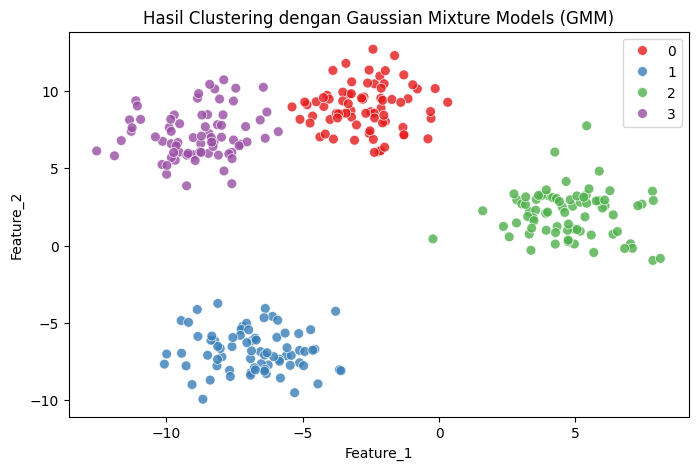

In [5]:
# 1. Menunjukkan Pentingnya Standarisasi (Scaling) Data
# Membuat variabel dengan skala timpang
df_unscaled = df_blobs[['Feature_1', 'Feature_2']].copy()
df_unscaled['Feature_2'] = df_unscaled['Feature_2'] * 1000  # Skala Feature_2 sekarang ribuan kali lipat

scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_unscaled), columns=['Feature_1_Scaled', 'Feature_2_Scaled'])

print("Varians Data Belum Diskalakan:")
print(df_unscaled.var().apply(lambda x: f"{x:,.2f}"))

print("\nVarians Data Setelah Standarisasi (Z-Score):")
print(df_scaled.var().apply(lambda x: f"{x:,.2f}"))


# 2. Gaussian Mixture Models (GMM)
# Fit GMM dengan 4 komponen
gmm = GaussianMixture(n_components=4, random_state=42)
gmm_clusters = gmm.fit_predict(df_blobs[['Feature_1', 'Feature_2']])
probabilities = gmm.predict_proba(df_blobs[['Feature_1', 'Feature_2']])

# Menampilkan probabilitas kepemilikan titik pertama terhadap keempat klaster
print(f"\nProbabilitas titik data ke-0 masuk ke setiap klaster (GMM):\n {np.round(probabilities[0], 4)}")

# Visualisasi Hasil GMM
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Feature_1', y='Feature_2', hue=gmm_clusters, palette='Set1', data=df_blobs, s=50, alpha=0.8)
plt.title('Hasil Clustering dengan Gaussian Mixture Models (GMM)')
plt.show()